## 1. Load the data and libraries

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score
import xgboost as xgb
import warnings; warnings.filterwarnings('ignore')

cols = ['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'fico_range_low', 'term',
        'emp_length', 'home_ownership', 'purpose', 'open_acc', 'revol_util', 'total_acc',
        'loan_status', 'issue_d', 'last_pymnt_d']
# Download the full LendingClub dataset from Kaggle (no manual upload needed)
import kagglehub, os
folder = kagglehub.dataset_download("wordsforthewise/lending-club")
found = [os.path.join(r, f) for r, _, fs in os.walk(folder) for f in fs
         if f.lower().startswith('accepted') and (f.endswith('.csv') or f.endswith('.csv.gz'))]
csv_files = [f for f in found if f.endswith('.csv')]
DATA_FILE = csv_files[0] if csv_files else found[0]
print("Using:", DATA_FILE)

df = pd.read_csv(DATA_FILE, usecols=cols, low_memory=False)
print(f"Shape: {df.shape}")
if len(df) < 2_000_000:
    print("WARNING: fewer rows than expected (~2.26 million). The file may be incomplete.")

Using Colab cache for faster access to the 'lending-club' dataset.
Using: /kaggle/input/lending-club/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv
Shape: (2260701, 16)


## 2. Define prepayment (the target)

In [2]:
df = df[df['loan_status'] == 'Fully Paid'].copy()          # only loans that were fully repaid
df = df.dropna(subset=['issue_d', 'last_pymnt_d'])
df['issue_d']      = pd.to_datetime(df['issue_d'], format='%b-%Y')
df['last_pymnt_d'] = pd.to_datetime(df['last_pymnt_d'], format='%b-%Y')
df['term'] = df['term'].astype(str).str.strip().str.replace(' months', '').astype(int)

df['months_to_payoff'] = ((df['last_pymnt_d'].dt.year - df['issue_d'].dt.year) * 12
                          + (df['last_pymnt_d'].dt.month - df['issue_d'].dt.month))
df['prepaid_early'] = (df['months_to_payoff'] <= df['term'] - 3).astype(int)
print("Fully paid loans:", len(df))

Fully paid loans: 1076751


## 3. Remove a hidden bias (loans that had no time to finish normally)


In [3]:
data_end = df['last_pymnt_d'].max()
scheduled_end = df['issue_d'] + df['term'].apply(lambda t: pd.DateOffset(months=int(t)))
before = len(df)
df = df[scheduled_end <= data_end].copy()
print(f"Data ends: {data_end:%b %Y}")
print(f"Loans kept: {len(df):,} of {before:,} (removed {before-len(df):,} loans that could not yet finish on schedule)")
print(df['term'].value_counts().rename('loans by term (months)'))
print(f"\nEarly prepayment rate: {df['prepaid_early'].mean():.2%}")

Data ends: Mar 2019
Loans kept: 658,666 of 1,076,751 (removed 418,085 loans that could not yet finish on schedule)
term
36    607955
60     50711
Name: loans by term (months), dtype: int64

Early prepayment rate: 61.31%


## 4. Exploratory data analysis

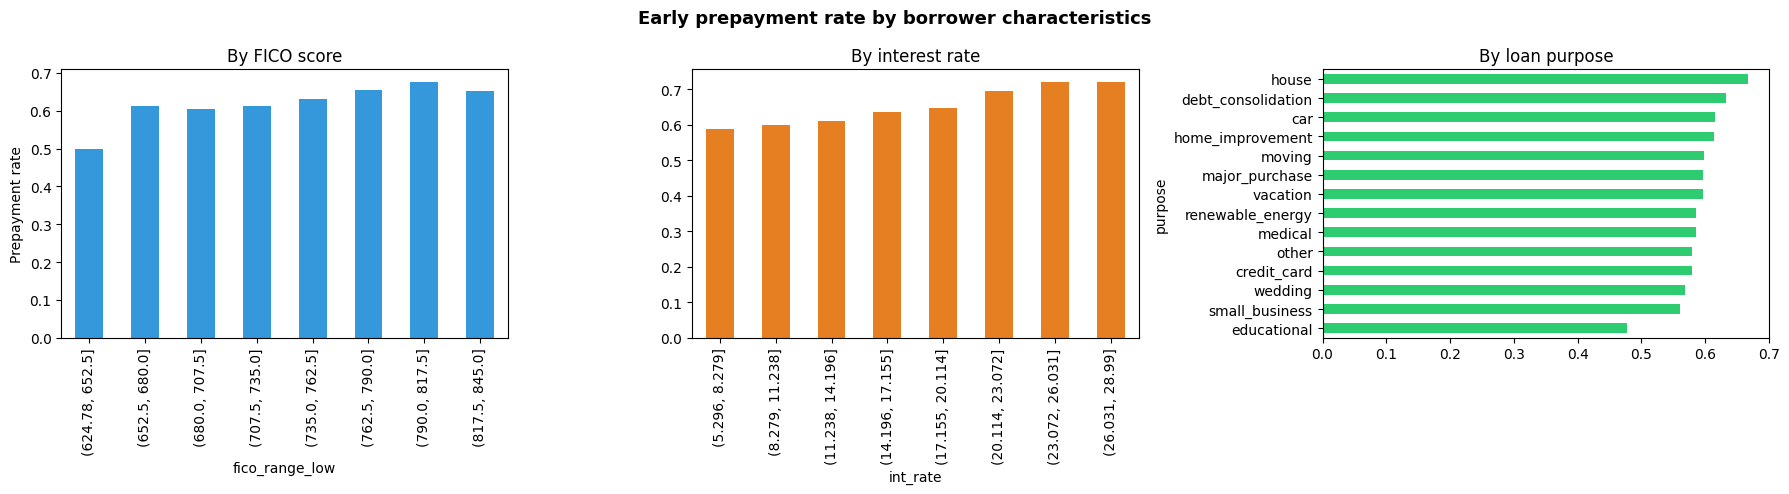

In [4]:
df_eda = df.dropna(subset=['fico_range_low', 'int_rate'])
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Early prepayment rate by borrower characteristics', fontsize=13, fontweight='bold')
df_eda.groupby(pd.cut(df_eda['fico_range_low'], bins=8))['prepaid_early'].mean().plot(kind='bar', ax=axes[0], color='#3498db')
axes[0].set_title('By FICO score'); axes[0].set_ylabel('Prepayment rate')
df_eda.groupby(pd.cut(df_eda['int_rate'], bins=8))['prepaid_early'].mean().plot(kind='bar', ax=axes[1], color='#e67e22')
axes[1].set_title('By interest rate')
df_eda.groupby('purpose')['prepaid_early'].mean().sort_values().plot(kind='barh', ax=axes[2], color='#2ecc71')
axes[2].set_title('By loan purpose')
plt.tight_layout(); plt.show()

## 5. Feature engineering (18 features)
All features are known when the loan is issued.

In [5]:
df = df.dropna(subset=['annual_inc', 'dti', 'revol_util', 'open_acc', 'total_acc', 'fico_range_low', 'int_rate', 'installment'])
df = df[df['annual_inc'] > 0]
df['emp_length'] = df['emp_length'].astype(str).str.extract(r'(\d+)')[0].astype(float).fillna(0)
df.rename(columns={'fico_range_low': 'fico_score'}, inplace=True)

le_home, le_purpose = LabelEncoder(), LabelEncoder()
df['home_ownership_enc'] = le_home.fit_transform(df['home_ownership'].astype(str))
df['purpose_enc']        = le_purpose.fit_transform(df['purpose'].astype(str))

df['loan_to_income']          = df['loan_amnt'] / df['annual_inc']
df['installment_to_income']   = df['installment'] / (df['annual_inc'] / 12)
df['credit_utilization_risk'] = (df['revol_util'] > 70).astype(int)
df['high_fico']               = (df['fico_score'] > 720).astype(int)
df['high_rate']               = (df['int_rate'] > 18).astype(int)

FEATURES = ['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'fico_score', 'term',
            'emp_length', 'open_acc', 'revol_util', 'total_acc', 'home_ownership_enc', 'purpose_enc',
            'loan_to_income', 'installment_to_income', 'credit_utilization_risk', 'high_fico', 'high_rate']
X, y = df[FEATURES], df['prepaid_early']
print(f"Features: {len(FEATURES)} | Samples: {len(X):,} | Prepayment rate: {y.mean():.2%}")

Features: 18 | Samples: 658,303 | Prepayment rate: 61.30%


## 6. Train/test split (stratified 80/20)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
majority = max(y_test.mean(), 1 - y_test.mean())
print(f"Accuracy of always predicting the majority class: {majority:.2%}  <- any model must beat this")

Train: 526,642 | Test: 131,661
Accuracy of always predicting the majority class: 61.30%  <- any model must beat this


## 7. Baseline: Logistic Regression

In [7]:
scaler = StandardScaler().fit(X_train)
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(scaler.transform(X_train), y_train)
lr_proba = lr.predict_proba(scaler.transform(X_test))[:, 1]
lr_auc = roc_auc_score(y_test, lr_proba)
lr_acc = accuracy_score(y_test, (lr_proba > 0.5).astype(int))
print(f"Logistic Regression | ROC-AUC: {lr_auc:.4f} | Accuracy: {lr_acc:.2%}")

Logistic Regression | ROC-AUC: 0.6041 | Accuracy: 61.83%


## 8. Main model: XGBoost

In [8]:
xgb_model = xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)
xgb_proba = xgb_model.predict_proba(X_test)[:, 1]
xgb_pred  = (xgb_proba > 0.5).astype(int)
xgb_auc = roc_auc_score(y_test, xgb_proba)
xgb_acc = accuracy_score(y_test, xgb_pred)
print(f"XGBoost             | ROC-AUC: {xgb_auc:.4f} | Accuracy: {xgb_acc:.2%}")

XGBoost             | ROC-AUC: 0.6179 | Accuracy: 62.49%


## 9. Evaluation

                  precision    recall  f1-score   support

Paid on schedule       0.55      0.17      0.26     50948
   Prepaid early       0.64      0.91      0.75     80713

        accuracy                           0.62    131661
       macro avg       0.59      0.54      0.51    131661
    weighted avg       0.60      0.62      0.56    131661



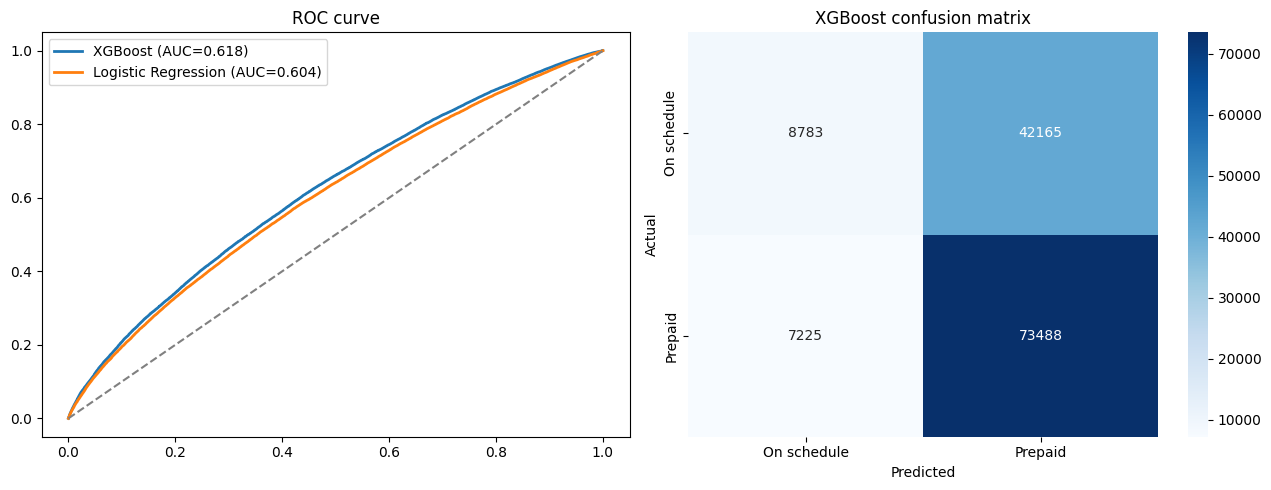

In [9]:
print(classification_report(y_test, xgb_pred, target_names=['Paid on schedule', 'Prepaid early']))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for proba, name, auc in [(xgb_proba, 'XGBoost', xgb_auc), (lr_proba, 'Logistic Regression', lr_auc)]:
    fpr, tpr, _ = roc_curve(y_test, proba); axes[0].plot(fpr, tpr, lw=2, label=f'{name} (AUC={auc:.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray'); axes[0].set_title('ROC curve'); axes[0].legend()
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['On schedule', 'Prepaid'], yticklabels=['On schedule', 'Prepaid'])
axes[1].set_title('XGBoost confusion matrix'); axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 10. Which features drive prepayment?

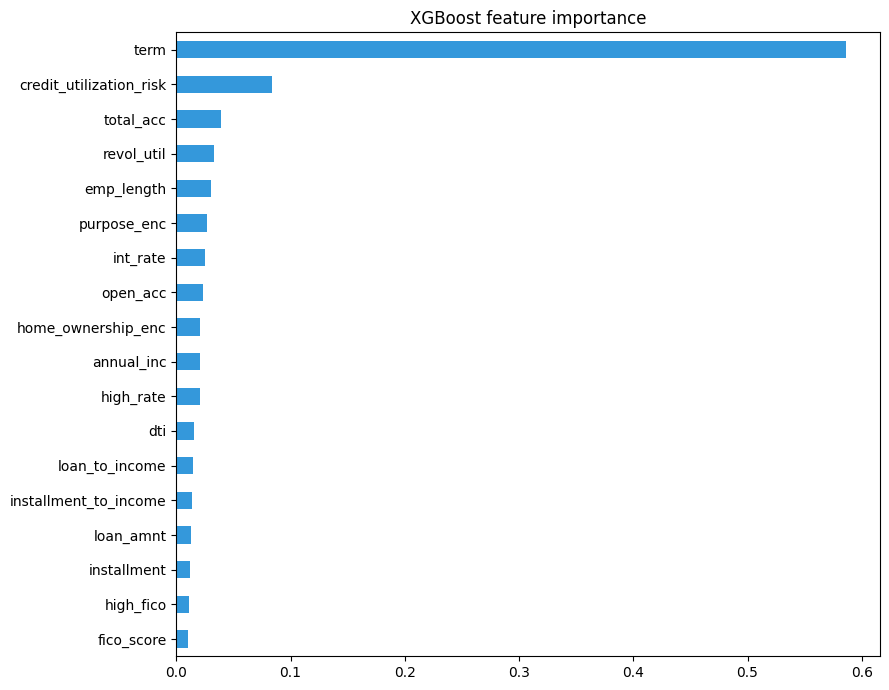

In [10]:
imp = pd.Series(xgb_model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind='barh', figsize=(9, 7), color='#3498db', title='XGBoost feature importance'); plt.tight_layout(); plt.show()